# Praktikum 1 : Exact NN dan Annoy pada data kafe

Exact NN index: [102  91  49]
Exact NN jarak: [0.         0.00118519 0.00269586]
Waktu Exact: 0.3106 ms

Annoy NN index: [102, 91, 53]
Annoy NN jarak: [np.float64(0.0), np.float64(0.0011851853399430698), np.float64(0.002872546413900998)]
Waktu Annoy: 0.119 ms


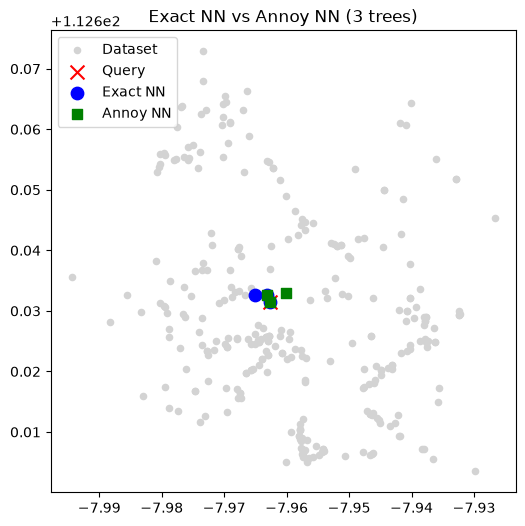

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time

from annoy import AnnoyIndex

# 1. Dataset 2D
np.random.seed(42)
import pandas as pd
df = pd.read_csv('../../dataset_pbl/cafes.csv')
features = ['latitude', 'longitude', 'rating', 'review_count', 'price_min']
df[features] = df[features].fillna(df[features].mean())
X = df[['latitude', 'longitude']].to_numpy()
n_points = len(X)

# Query point (ambil salah satu titik random)
query = X[np.random.randint(0, n_points)]

# 2. Exact NN (brute force)
start = time.perf_counter()
distances = np.linalg.norm(X - query, axis=1)
idx_exact = np.argsort(distances)[:3]  # ambil 3 terdekat
time_exact = time.perf_counter() - start

print("Exact NN index:", idx_exact)
print("Exact NN jarak:", distances[idx_exact])
print("Waktu Exact:", round(time_exact*1000, 4), "ms")

# 3. Annoy NN (3 tree)
f = 2  # dimensi
t = AnnoyIndex(f, 'euclidean')
for i, vec in enumerate(X):
    t.add_item(i, vec)

t.build(3)  # 3 trees

start = time.perf_counter()
idx_ann = t.get_nns_by_vector(query, 3)  # cari 3 NN
time_ann = time.perf_counter() - start

print("\nAnnoy NN index:", idx_ann)
print("Annoy NN jarak:", [np.linalg.norm(X[i]-query) for i in idx_ann])
print("Waktu Annoy:", round(time_ann*1000, 4), "ms")

# 4. Visualisasi hasil
plt.figure(figsize=(6,6))
plt.scatter(X[:,0], X[:,1], c="lightgray", s=20, label="Dataset")
plt.scatter(query[0], query[1], c="red", marker="x", s=100, label="Query")

# Exact NN ditandai biru
plt.scatter(X[idx_exact,0], X[idx_exact,1], c="blue", s=80, label="Exact NN")

# Annoy NN ditandai hijau
plt.scatter(X[idx_ann,0], X[idx_ann,1], c="green", s=50, marker="s", label="Annoy NN")

plt.legend()
plt.title("Exact NN vs Annoy NN (3 trees)")
plt.show()

In [2]:
import pandas as pd
from IPython.display import display

def uji_annoy(metric='euclidean', n_trees=3, n_points=1000):
    np.random.seed(42)
    x = df[['latitude', 'longitude']].iloc[:n_points].to_numpy()
    query = x[np.random.randint(0, n_points)]

    t_mulai = time.perf_counter()
    if metric == 'euclidean':
        jarak_exact = np.linalg.norm(x - query, axis=1)
    else:
        norm_x = x / np.linalg.norm(x, axis=1, keepdims=True)
        norm_q = query / np.linalg.norm(query)
        jarak_exact = np.linalg.norm(norm_x - norm_q, axis=1)
    idx_exact = np.argsort(jarak_exact)[:3].tolist()
    t_exact = (time.perf_counter() - t_mulai) * 1000

    t_index = AnnoyIndex(2, metric)
    t_index.set_seed(42)
    for i, vec in enumerate(x):
        t_index.add_item(i, vec)
    t_index.build(n_trees, n_jobs=1)

    t_mulai_ann = time.perf_counter()
    idx_ann = t_index.get_nns_by_vector(query, 3)
    t_ann = (time.perf_counter() - t_mulai_ann) * 1000

    return {
        'Distance Metrics': metric.capitalize(), 'Tree': n_trees,
        'Jumlah data': n_points,
        'Hasil Index terdekat ENN vs ANN': f'{idx_exact}, {idx_ann}',
        'Waktu komputasi ENN vs ANN (ms)': f'{t_exact:.6f}, {t_ann:.6f}'
    }

hasil_2d = []
for metric in ['euclidean', 'angular']:
    for n_trees, n_points in [(3, 256), (8, 256), (3, len(df))]:
        hasil_2d.append(uji_annoy(metric, n_trees, n_points))

tabel_2d = pd.DataFrame(hasil_2d)
with pd.option_context('display.max_colwidth', None):
    display(tabel_2d)

,Distance Metrics,Tree,Jumlah data,Hasil Index terdekat ENN vs ANN,Waktu komputasi ENN vs ANN (ms)
0,Euclidean,3,256,"[102, 91, 49], [102, 91, 53]","0.113900, 0.026200"
1,Euclidean,8,256,"[102, 91, 49], [102, 91, 49]","0.061100, 0.046000"
2,Euclidean,3,302,"[102, 91, 49], [102, 91, 49]","0.079800, 0.018000"
3,Angular,3,256,"[102, 44, 183], [65, 85, 69]","0.080900, 0.033600"
4,Angular,8,256,"[102, 44, 183], [88, 4, 165]","0.076400, 0.026200"
5,Angular,3,302,"[102, 44, 183], [276, 219, 5]","0.120800, 0.022800"


In [3]:
from sklearn.metrics.pairwise import euclidean_distances

n_tracks = len(df)
n_features = len(features)
n_trees = 8
np.random.seed(42)
x = df[features].to_numpy(dtype=np.float32)
query = x[:1].copy()

hasil_kafe = []
for metric in ['euclidean', 'angular']:
    t_mulai = time.perf_counter()
    if metric == 'euclidean':
        jarak_semua = euclidean_distances(query, x)[0]
    else:
        norm_x = x / np.linalg.norm(x, axis=1, keepdims=True)
        norm_q = query / np.linalg.norm(query)
        jarak_semua = np.linalg.norm(norm_x - norm_q, axis=1)
    exact_idx = np.argsort(jarak_semua)[:5].tolist()
    exact_time = time.perf_counter() - t_mulai

    annoy_index = AnnoyIndex(n_features, metric)
    annoy_index.set_seed(42)
    for i, vec in enumerate(x):
        annoy_index.add_item(i, vec)
    annoy_index.build(n_trees, n_jobs=1)

    t_mulai_ann = time.perf_counter()
    annoy_idx = annoy_index.get_nns_by_vector(query[0], 5)
    annoy_time = time.perf_counter() - t_mulai_ann

    hasil_kafe.append({
        'Distance Metrics': metric.capitalize(), 'Tree': n_trees,
        'Jumlah data': n_tracks,
        'Hasil Index terdekat ENN vs ANN': f'{exact_idx}, {annoy_idx}',
        'Waktu komputasi ENN vs ANN (detik)': f'{exact_time:.6f}, {annoy_time:.6f}'
    })
    del annoy_index

tabel_kafe = pd.DataFrame(hasil_kafe)
with pd.option_context('display.max_colwidth', None):
    display(tabel_kafe)

,Distance Metrics,Tree,Jumlah data,Hasil Index terdekat ENN vs ANN,Waktu komputasi ENN vs ANN (detik)
0,Euclidean,8,302,"[0, 85, 225, 201, 115], [0, 85, 225, 201, 115]","0.001557, 0.000023"
1,Angular,8,302,"[0, 85, 225, 115, 201], [0, 85, 225, 115, 201]","0.000112, 0.000033"
